In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load dataset directly
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
df = pd.read_csv(url)

# Display first five rows
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [2]:
print("Dataset shape:", df.shape)
print("\nColumn information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
df.describe()

Dataset shape: (20640, 10)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

Missing values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
medi

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


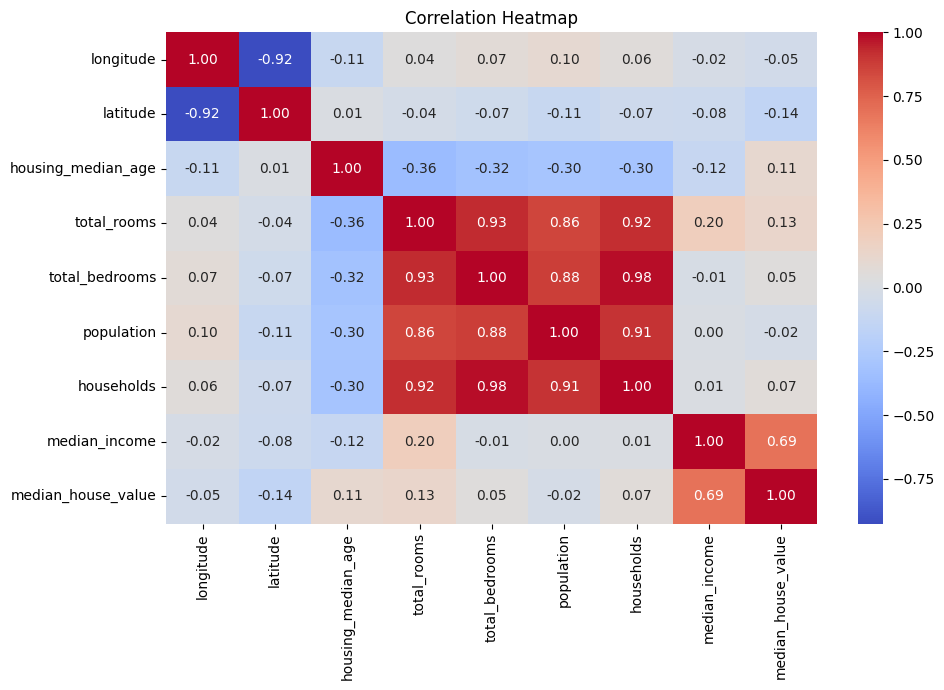

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [4]:
# Target: value we want to predict
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

# Identify numerical and categorical columns
num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(exclude="number").columns

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 16512
Testing rows: 4128


In [5]:
# Numerical preprocessing
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("interactions", PolynomialFeatures(
        degree=2, interaction_only=True, include_bias=False
    )),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the appropriate preprocessing to each column type
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

In [6]:
# Ordinary Least Squares
ols_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

ols_model.fit(X_train, y_train)

# Ridge regression with GridSearchCV
ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

ridge_search = GridSearchCV(
    ridge_pipeline,
    {"model__alpha": [0.1, 1, 10, 100]},
    cv=3,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

ridge_search.fit(X_train, y_train)

# Lasso regression with GridSearchCV
lasso_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Lasso(max_iter=10000))
])

lasso_search = GridSearchCV(
    lasso_pipeline,
    {"model__alpha": [0.1, 1, 10, 100]},
    cv=3,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

lasso_search.fit(X_train, y_train)

print("Best Ridge alpha:", ridge_search.best_params_)
print("Best Lasso alpha:", lasso_search.best_params_)

Best Ridge alpha: {'model__alpha': 0.1}
Best Lasso alpha: {'model__alpha': 0.1}


c:\Users\junai\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.461e+13, tolerance: 2.207e+10
  model = cd_fast.enet_coordinate_descent(


In [7]:
models = {
    "Linear Regression (OLS)": ols_model,
    "Ridge Regression": ridge_search.best_estimator_,
    "Lasso Regression": lasso_search.best_estimator_
}

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2 Score": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("RMSE")

results_df.round(2)

,Model,MAE,RMSE,R2 Score
0,Linear Regression (OLS),47282.11,66788.30,0.66
1,Ridge Regression,47577.65,67119.39,0.66
2,Lasso Regression,48121.19,67683.11,0.65


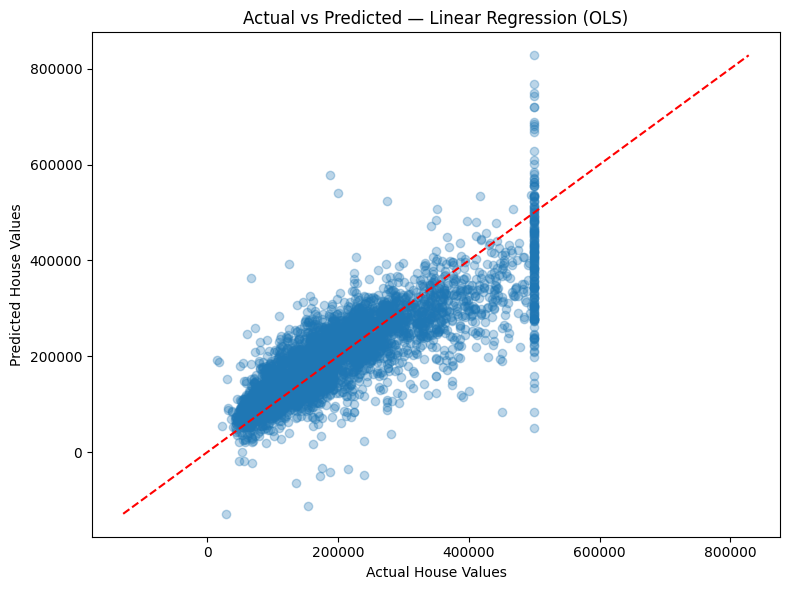

In [8]:
best_model_name = results_df.iloc[0]["Model"]
best_predictions = predictions[best_model_name]

plt.figure(figsize=(8, 6))
plt.scatter(y_test, best_predictions, alpha=0.3)

# Ideal predictions would lie on this diagonal line
minimum = min(y_test.min(), best_predictions.min())
maximum = max(y_test.max(), best_predictions.max())

plt.plot([minimum, maximum], [minimum, maximum], "r--")

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title(f"Actual vs Predicted — {best_model_name}")
plt.tight_layout()
plt.show()

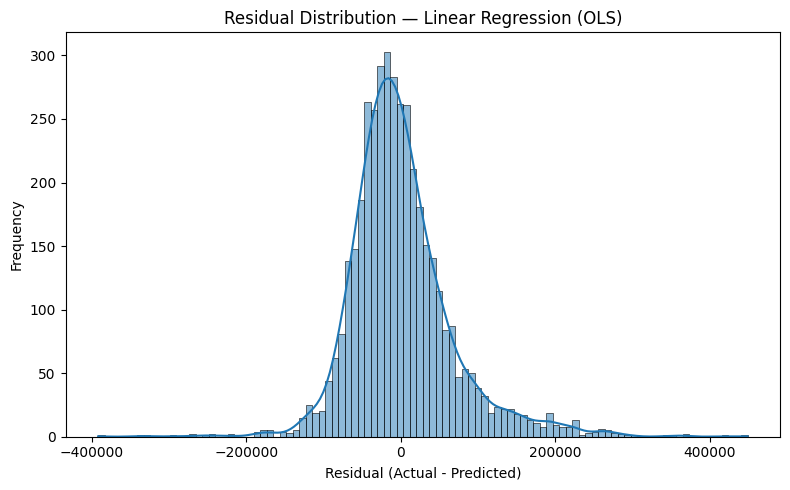

In [9]:
residuals = y_test - best_predictions

plt.figure(figsize=(8, 5))
sns.histplot(residuals, kde=True)

plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title(f"Residual Distribution — {best_model_name}")
plt.tight_layout()
plt.show()

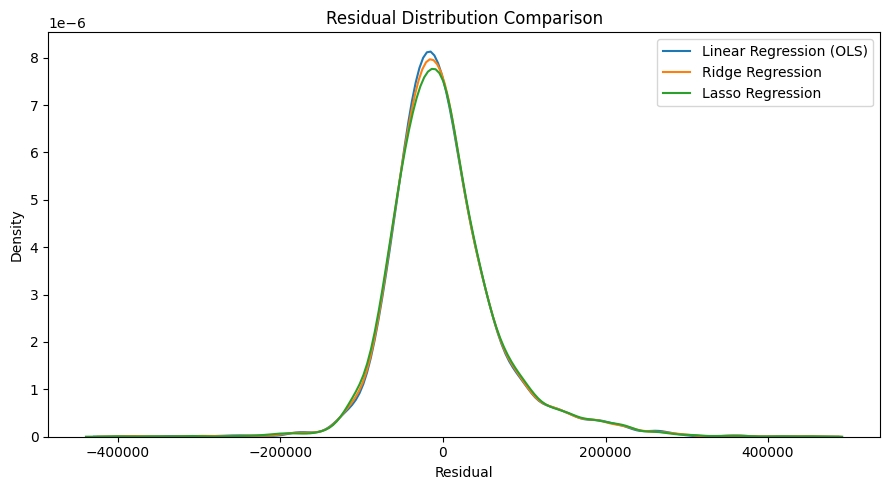

In [10]:
plt.figure(figsize=(9, 5))

for name, y_pred in predictions.items():
    residuals = y_test - y_pred
    sns.kdeplot(residuals, label=name)

plt.xlabel("Residual")
plt.ylabel("Density")
plt.title("Residual Distribution Comparison")
plt.legend()
plt.tight_layout()
plt.show()

## Conclusion

In this project, I developed a house price prediction model using the California Housing dataset. I handled missing values, encoded categorical data, scaled numerical features, and created interaction features.

I trained and compared Linear Regression, Ridge Regression, and Lasso Regression using MAE, RMSE, and R². I also used GridSearchCV to find suitable alpha values for Ridge and Lasso.

Based on the evaluation results, Linear Regression (OLS) achieved the lowest RMSE of 66788.30 and an R² score of 0.66. The actual-versus-predicted plot and residual distribution helped me assess prediction accuracy and model errors.

This project helped me understand regression modeling, regularization, feature engineering, and model evaluation.